# 02 · Stylized facts of daily FX returns

The proposal rests on two well-known properties of currency returns: they are close to unpredictable, while their volatility clusters and so is predictable. This notebook checks both on our data, along with fat tails.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fxml.config import load_config
from fxml import viz

cfg = load_config()
viz.apply_style()
colors = viz.pair_colors(cfg.pairs)
panel = pd.read_parquet(cfg.paths.processed / "daily_bars.parquet")
macro = pd.read_parquet(cfg.paths.processed / "macro.parquet")
rates = pd.read_parquet(cfg.paths.processed / "policy_rates.parquet")
pairs = list(cfg.pairs)
pd.set_option("display.precision", 4)

from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

## Summary statistics

Annualised figures use 252 trading days. Ljung–Box p-values test for autocorrelation up to 10 lags: high for returns means no linear predictability, near zero for squared returns means volatility clustering.

In [2]:
rows = {}
for pair in pairs:
    d = panel.xs(pair, level="symbol")
    r = d["ret"].dropna()
    rows[pair] = {
        "ann_return_pct": 100 * 252 * r.mean(),
        "ann_vol_pct": 100 * np.sqrt(252) * r.std(),
        "skew": stats.skew(r),
        "excess_kurtosis": stats.kurtosis(r),
        "acf1_returns": r.autocorr(1),
        "acf1_abs_returns": r.abs().autocorr(1),
        "ljung_box_p_returns": acorr_ljungbox(r, lags=[10])["lb_pvalue"].iloc[0],
        "ljung_box_p_squared": acorr_ljungbox(r**2, lags=[10])["lb_pvalue"].iloc[0],
        "corr_rv_parkinson": d[["rv", "parkinson"]].corr().iloc[0, 1],
    }
summary = pd.DataFrame(rows).T
summary.to_csv(cfg.paths.reports / "tables" / "stylized_facts.csv")
summary

,ann_return_pct,ann_vol_pct,skew,excess_kurtosis,acf1_returns,acf1_abs_returns,ljung_box_p_returns,ljung_box_p_squared,corr_rv_parkinson
EURUSD,-0.3276,8.6694,0.0929,2.4357,0.0094,0.1549,3.5248e-01,3.9715e-267,0.8407
GBPUSD,-1.2438,9.1742,-0.8055,11.0275,0.0389,0.2012,1.1549e-02,2.4327e-94,0.9046
USDJPY,1.3974,9.7668,-0.1816,4.8891,-0.0210,0.1832,3.3759e-01,1.4582e-116,0.8686
USDCHF,-2.0858,10.2497,-4.7697,162.1021,-0.0199,0.1363,4.4628e-01,6.7101e-01,0.9853
AUDUSD,-0.2394,12.2090,-0.3354,10.5184,-0.0390,0.2434,2.7276e-04,0.0000e+00,0.8655
USDCAD,0.8930,8.5432,0.0900,3.4338,-0.0287,0.2430,8.3915e-06,0.0000e+00,0.8220
NZDUSD,-0.8513,12.1919,-0.2763,3.2625,-0.0086,0.2065,4.3846e-02,0.0000e+00,0.8216


## Volatility clusters, returns do not

Autocorrelation of daily returns against autocorrelation of absolute returns, up to 30 days. The shaded band is the 95% range expected from pure noise.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/facts_autocorrelation.png')

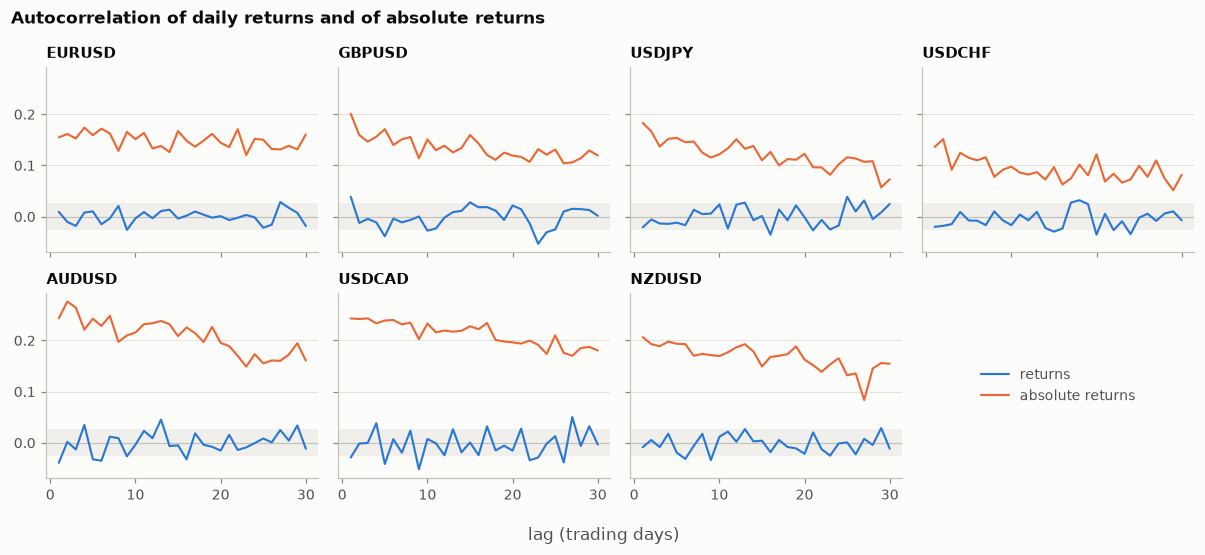

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5), sharex=True, sharey=True)
lags = np.arange(1, 31)
for ax, pair in zip(axes.flat, pairs):
    r = panel.xs(pair, level="symbol")["ret"].dropna()
    band = 1.96 / np.sqrt(len(r))
    ax.axhspan(-band, band, color=viz.SHADE, lw=0)
    ax.axhline(0, color=viz.BASELINE, lw=0.8)
    ax.plot(lags, acf(r, nlags=30)[1:], color=viz.CATEGORICAL[0], label="returns")
    ax.plot(lags, acf(r.abs(), nlags=30)[1:], color=viz.CATEGORICAL[1], label="absolute returns")
    ax.set_title(pair)
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.supxlabel("lag (trading days)", color=viz.INK_SECONDARY)
fig.suptitle("Autocorrelation of daily returns and of absolute returns", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
viz.save(fig, "facts_autocorrelation")

## Realized volatility over time

Annualised realized volatility from 5-minute returns (20-day average). Grey bands mark the documented stress periods.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/facts_realized_volatility.png')

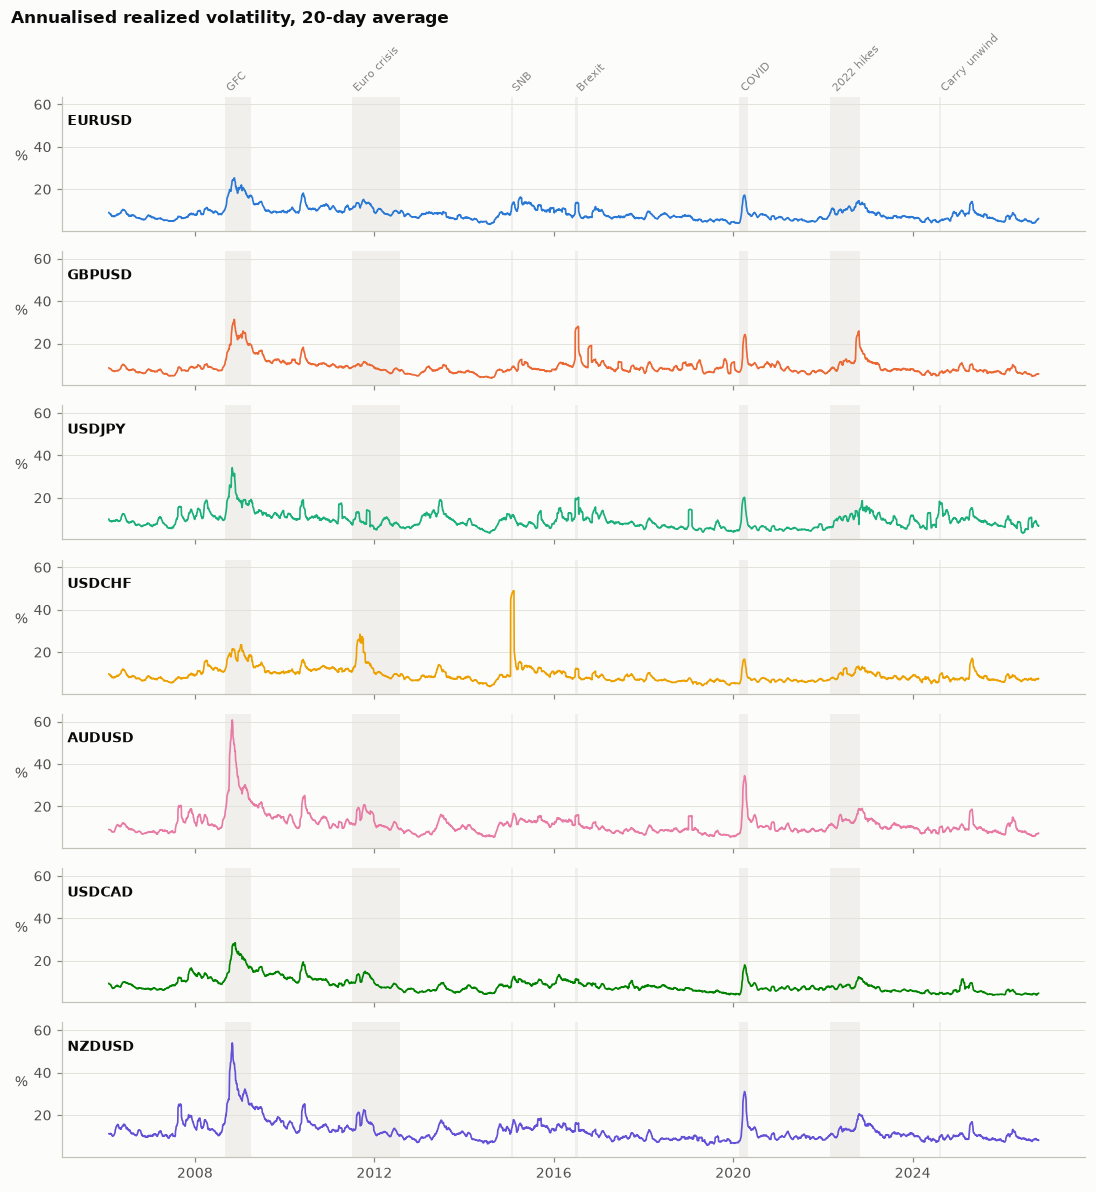

In [4]:
fig, axes = plt.subplots(7, 1, figsize=(10, 11), sharex=True, sharey=True)
for ax, pair in zip(axes, pairs):
    rv = panel.xs(pair, level="symbol")["rv"]
    vol = 100 * np.sqrt(252 * rv.rolling(20).mean())
    viz.shade_stress(ax, label=(pair == pairs[0]))
    ax.plot(vol.index, vol, color=colors[pair], lw=1.1)
    ax.set_title(pair, loc="left", y=0.72, x=0.005, fontsize=9)
    ax.set_ylabel("%", rotation=0, labelpad=8)
fig.suptitle("Annualised realized volatility, 20-day average", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
viz.save(fig, "facts_realized_volatility")

## Fat tails

Daily EUR/USD returns standardised by their own volatility, against a normal distribution. The log scale makes the tails visible.

PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/facts_fat_tails.png')

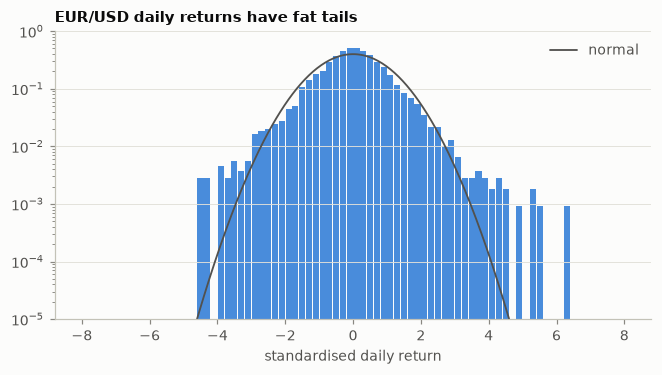

In [5]:
r = panel.xs("EURUSD", level="symbol")["ret"].dropna()
z = (r - r.mean()) / r.std()
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(-8, 8, 81)
ax.hist(z, bins=bins, density=True, color=colors["EURUSD"], alpha=0.85, rwidth=0.9)
grid = np.linspace(-8, 8, 400)
ax.plot(grid, stats.norm.pdf(grid), color=viz.INK_SECONDARY, lw=1.2, label="normal")
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.legend(loc="upper right")
ax.set(xlabel="standardised daily return", title="EUR/USD daily returns have fat tails")
viz.save(fig, "facts_fat_tails")

## Findings

- **Volatility levels.** Annualised volatility ranges from 8.5% (USD/CAD) to 12.2% (AUD/USD and NZD/USD); the commodity currencies are the most volatile.
- **Fat tails in every pair.** Excess kurtosis runs from 2.4 (EUR/USD) to 11 (GBP/USD, AUD/USD). For USD/CHF it reaches 162, almost entirely because of the −19.5% day on 15 January 2015.
- **Returns are barely autocorrelated.** Lag-one autocorrelations sit between −0.04 and +0.04.
  - The Ljung–Box test finds no linear dependence in EUR/USD, USD/JPY or USD/CHF.
  - It finds some in AUD/USD and USD/CAD (p < 0.001), and weakly in GBP/USD and NZD/USD.
  - That small structure is worth testing in RQ2, but on its own it is far too small to trade.
- **Volatility clusters strongly.** Absolute returns have lag-one autocorrelation of 0.14–0.24 and decay slowly over 30 days in every pair. Squared returns reject independence everywhere except USD/CHF, where the single 2015 shock swamps the test. This is the predictability RQ1 relies on.
- **Range estimators are a credible fallback.** Daily realized variance and the Parkinson estimator correlate 0.82–0.99.

**For modelling:**
- forecast *log* realized volatility, because of the heavy tails;
- compare volatility forecasts with QLIKE;
- report USD/CHF results with and without January 2015.
